In [264]:
import trenchripper as tr

import dask
import warnings
import copy
import random
import re
import umap
import scipy.stats
import anndata

import numpy as np
import pandas as pd
import seaborn as sns
import scipy as sp
import sklearn as skl
import dask.array as da
import scanpy as sc
import colorcet as cc
from tslearn.metrics import cdist_soft_dtw_normalized,cdist_soft_dtw,soft_dtw_alignment
from sklearn.metrics import silhouette_score

from matplotlib import pyplot as plt

random.seed(42)
np.random.seed(42)

dask_wd = '/home/lag36/scratch/lag36/dask/'

warnings.filterwarnings(action='once',category=UserWarning)

In [265]:
HEADPATH = '/home/lag36/scratch/lag36/2025-06-03_lLAG8-10_Merged-Analysis/2025-06-04_lLAG8_ExpNum-Fixed/'
rootpath = HEADPATH + '/2025-08-12_lLAG8_12Hour_Analysis/'
strong_effect_threshold = 1.25
n_neighbors = 10
z_score_thr_dir = rootpath + "/Z_Score_Thr_" + str(strong_effect_threshold) + "_N_Neighbors_" + str(n_neighbors)

In [266]:
clustering_df = pd.read_pickle(z_score_thr_dir + "/Pandas_Dataframe.pkl")
# clustering_an_df = anndata.read_h5ad(rootpath + "/AnnData_wSteadyState.h5ad")
an_df_clustree = anndata.read_h5ad(z_score_thr_dir+"/AnnData_nonRcompat.h5ad")
clustering_an_df = an_df_clustree.copy()

cluster_levels = ["L0","L1","L2","L3"]
df_clusters = pd.DataFrame(an_df_clustree.obs.copy())
df_clusters.index = df_clusters.index.astype(float)

COLS_CONTROL = ['control'] # B. subtilis
control_phenotypes_df =(pd
    .read_pickle(HEADPATH + "/2025-08-11_sgRNA_Timeseries_df.pkl")
    .loc[lambda df_:df_['Category'].isin(COLS_CONTROL)]
    .copy()
)

In [273]:
kernel_label_list = ['Kernel Trace: Delta time (s)','Kernel Trace: Septum Displacement Length Normalized','Kernel Trace: Length',\
'Kernel Trace: Width','Kernel Trace: mCherry mean_intensity','Kernel Trace: Instantaneous Growth Rate: Volume']
for kernel_label in kernel_label_list:
    clustering_df["8 Hours: " + kernel_label] = clustering_df[kernel_label].apply(lambda x: x[19])
    control_phenotypes_df["8 Hours: " + kernel_label] = control_phenotypes_df[kernel_label].apply(lambda x: x[19])

clustering_df['8 Hours: Kernel Trace: Delta time (hr)'] = clustering_df['8 Hours: Kernel Trace: Delta time (s)']/3600
clustering_df['8 Hours: Kernel Trace: Instantaneous Growth Rate: Volume'] = clustering_df['8 Hours: Kernel Trace: Instantaneous Growth Rate: Volume']/np.log(2)

control_phenotypes_df['8 Hours: Kernel Trace: Delta time (hr)'] = control_phenotypes_df['8 Hours: Kernel Trace: Delta time (s)']/3600
control_phenotypes_df['8 Hours: Kernel Trace: Instantaneous Growth Rate: Volume'] = control_phenotypes_df['8 Hours: Kernel Trace: Instantaneous Growth Rate: Volume']/np.log(2)

cluster_levels = ["L0","L1","L2","L3"]

umap_fig_df = clustering_an_df.obs.copy()[cluster_levels]
umap_fig_df["X Coord"] = clustering_an_df.obsm['X_umap'][:,0]
umap_fig_df["Y Coord"] = clustering_an_df.obsm['X_umap'][:,1]
umap_fig_df.index = umap_fig_df.index.astype(float).astype(int)
umap_fig_df = umap_fig_df.join(clustering_df.drop(columns=cluster_levels),on="opLAG1_id")

for cluster_level in cluster_levels:
    all_clusters = list(umap_fig_df[cluster_level].unique())
    colors = cc.glasbey_hv[:len(all_clusters)]
    # Create a dictionary mapping each category to a color
    reorder_cluster_dict = {cluster:i for i,cluster in enumerate(all_clusters)}
    color_dict = dict(zip(all_clusters, colors))
    umap_fig_df[cluster_level + " Color"] = umap_fig_df[cluster_level].astype(str).apply(lambda x: color_dict[x])

In [275]:
clusters_df = clustering_df.dropna(subset=["L0"])

In [277]:
cbar_label = ""
labels = ['8 Hours: Kernel Trace: Delta time (hr)','8 Hours: Kernel Trace: Septum Displacement Length Normalized',\
          '8 Hours: Kernel Trace: Length','8 Hours: Kernel Trace: Width',\
          '8 Hours: Kernel Trace: mCherry mean_intensity','8 Hours: Kernel Trace: Instantaneous Growth Rate: Volume']
label_names = [r'$ \tau $',r'$ L_{S} $',r'$ L $',r'$ W $',r'$ I_{rpsL} $',r'$ \lambda $']#,'NC',r'$N_{n}$']
# nuc_labels = ['8 Hours: Kernel Trace: Total Nucleoid Area per Cell Area','8 Hours: Kernel Trace: Number of Nucleoids']
all_labels = labels #+ nuc_labels
label_percentiles = [7,0.5,7,7,7,7]#7,7]

title_list = ["Interdivision Time (hr)","Septum Error (%)","Length $(\mu m)$","Width $(\mu m)$",\
              "mKate2 Mean Intensity (AU)","Growth Rate (1/hr)"]#,"NC Ratio","N Nucleoids"]

median_vals_dict = {**control_phenotypes_df[labels].median().to_dict()}#,**control_nucleoid_df[nuc_labels].median().to_dict()}
median_properties = clusters_df.groupby("L3")[all_labels].median()

min_vals = []
max_vals = []
for i,label in enumerate(all_labels):
    vmin,vmax = np.nanpercentile(clusters_df[label],label_percentiles[i]),np.nanpercentile(clusters_df[label],100-label_percentiles[i])
    vcenter = median_vals_dict[label]
    min_deviation,max_deviation = (vcenter-vmin,vmax-vcenter)
    if min_deviation>max_deviation:
        vmax = vcenter + min_deviation
    else:
        vmin = vcenter - max_deviation
    min_vals.append(vmin)
    max_vals.append(vmax)

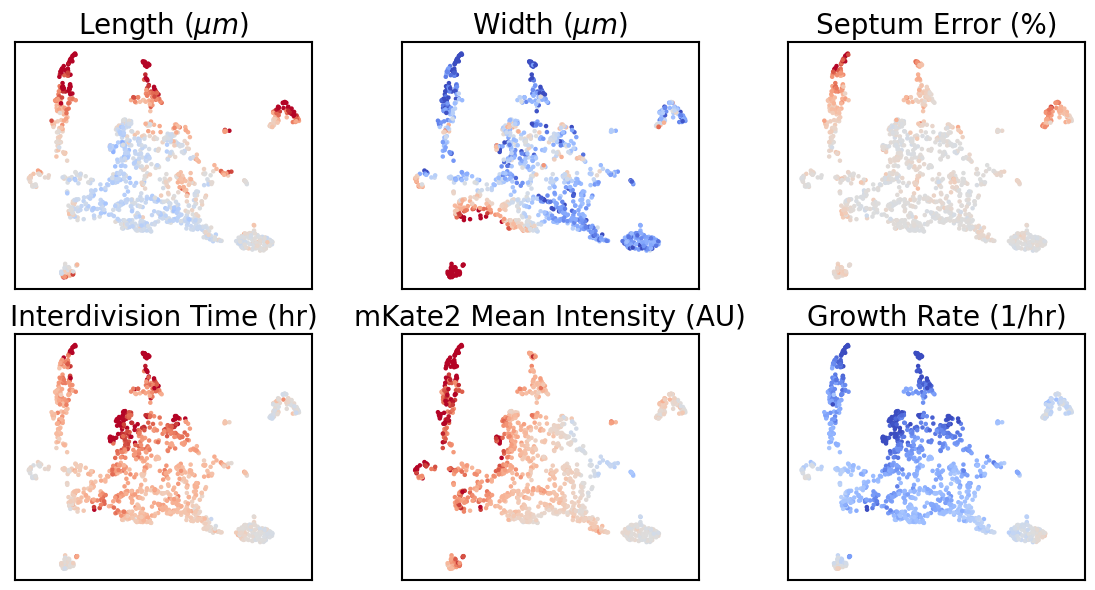

In [291]:
phenotype_indices = [2,3,1]
pheno_labels_of_interest = [all_labels[idx] for idx in phenotype_indices]
title_list_of_interest = [title_list[idx] for idx in phenotype_indices]
min_vals_of_interest = [min_vals[idx] for idx in phenotype_indices]
max_vals_of_interest = [max_vals[idx] for idx in phenotype_indices]
# cbar_ticks_of_interest = [cbar_ticks_list[idx] for idx in phenotype_indices]
fig = plt.figure(figsize=(11,6))
for i,pheno_label in enumerate(pheno_labels_of_interest):
    ax = plt.subplot(2,3,i+1)
    plt.title(str(title_list_of_interest[i]), fontsize=20)
    scatterout = plt.scatter(umap_fig_df["X Coord"],umap_fig_df["Y Coord"],
                c=umap_fig_df[pheno_label],s=5,zorder=1,\
                vmin=min_vals_of_interest[i],vmax=max_vals_of_interest[i],cmap="coolwarm")
    plt.yticks([])
    plt.xticks([])
    if i == 0:
        plt.ylabel("", fontsize=18)
    elif i == 1:
        plt.xlabel("", fontsize=18)
        
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)  # Set the thickness of the frame. Adjust the number to change the thickness.

phenotype_indices = [0,4,5]
pheno_labels_of_interest = [all_labels[idx] for idx in phenotype_indices]
title_list_of_interest = [title_list[idx] for idx in phenotype_indices]
min_vals_of_interest = [min_vals[idx] for idx in phenotype_indices]
max_vals_of_interest = [max_vals[idx] for idx in phenotype_indices]
for i,pheno_label in enumerate(pheno_labels_of_interest):    
    ax = plt.subplot(2,3,i+4)
    plt.title(str(title_list_of_interest[i]), fontsize=20)
    scatterout = plt.scatter(umap_fig_df["X Coord"],umap_fig_df["Y Coord"],
                c=umap_fig_df[pheno_label],s=5,zorder=1,\
                vmin=min_vals_of_interest[i],vmax=max_vals_of_interest[i],cmap="coolwarm")
    plt.yticks([])
    plt.xticks([])
    if i == 0:
        plt.ylabel("", fontsize=18)
    elif i == 1:
        plt.xlabel("", fontsize=18)
        
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)  # Set the thickness of the frame. Adjust the number to change the thickness.

plt.tight_layout()
fig.subplots_adjust(wspace=0.3)

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(
/tmp/ipykernel_1739629/1832662519.py:52: UserWarning: This figure includes Axes that are not c

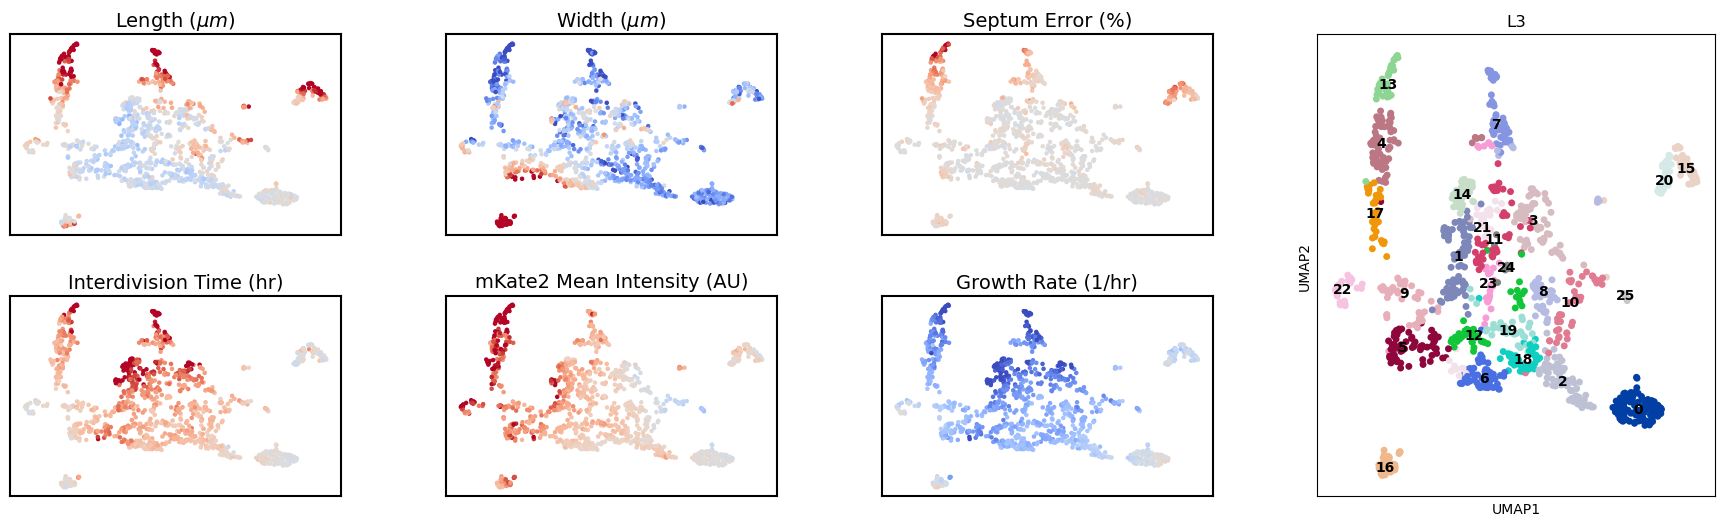

In [317]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import pandas as pd
import scanpy as sc

# --- Step 1: Setup Gridspec Layout ---
fig = plt.figure(figsize=(22, 6))  # adjust width to fit cluster plot
gs = gridspec.GridSpec(2, 4, width_ratios=[1, 1, 1, 1.2], wspace=0.3, hspace=0.3)

# --- Step 2: First row of 3 scatter plots ---
phenotype_indices = [2,3,1]
pheno_labels_of_interest = [all_labels[idx] for idx in phenotype_indices]
title_list_of_interest = [title_list[idx] for idx in phenotype_indices]
min_vals_of_interest = [min_vals[idx] for idx in phenotype_indices]
max_vals_of_interest = [max_vals[idx] for idx in phenotype_indices]

for i, pheno_label in enumerate(pheno_labels_of_interest):
    ax = fig.add_subplot(gs[0, i])
    ax.set_title(str(title_list_of_interest[i]), fontsize=14)
    scatterout = ax.scatter(umap_fig_df["X Coord"], umap_fig_df["Y Coord"],
                c=umap_fig_df[pheno_label], s=5, zorder=1,
                vmin=min_vals_of_interest[i], vmax=max_vals_of_interest[i], cmap="coolwarm")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

# --- Step 3: Second row of 3 scatter plots ---
phenotype_indices = [0,4,5]
pheno_labels_of_interest = [all_labels[idx] for idx in phenotype_indices]
title_list_of_interest = [title_list[idx] for idx in phenotype_indices]
min_vals_of_interest = [min_vals[idx] for idx in phenotype_indices]
max_vals_of_interest = [max_vals[idx] for idx in phenotype_indices]

for i, pheno_label in enumerate(pheno_labels_of_interest):
    ax = fig.add_subplot(gs[1, i])
    ax.set_title(str(title_list_of_interest[i]), fontsize=14)
    scatterout = ax.scatter(umap_fig_df["X Coord"], umap_fig_df["Y Coord"],
                c=umap_fig_df[pheno_label], s=5, zorder=1,
                vmin=min_vals_of_interest[i], vmax=max_vals_of_interest[i], cmap="coolwarm")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

# --- Step 4: Add scanpy UMAP plot in the rightmost column ---
# Generate the scanpy plot to an axis
ax_umap = fig.add_subplot(gs[:, 3])  # span both rows
sc.pl.umap(an_df_clustree, color='L3', legend_loc='on data', ax=ax_umap, show=False)

# --- Final layout adjustments ---
plt.tight_layout()
plt.show()

In [318]:
an_df_clustree.obs.loc[an_df_clustree.obs['L3'] == '0', 'Gene'].astype(str).value_counts().head(10)

Gene
pbpB    3
clpP    3
purE    2
rplF    2
tsf     2
ilvD    2
adk     2
leuA    2
rplP    2
rplV    2
Name: count, dtype: int64

In [306]:
an_df_clustree.obs.loc[an_df_clustree.obs['L3'] == '6', 'Gene'].astype(str).value_counts()

Gene
tyrS        3
hisB        3
hepT        2
ppaC        2
hisA        2
hisJ        2
yjlC        2
menB        2
sirB        2
dfrA        2
purS        1
purL        1
purH        1
purD        1
proA        1
hisC        1
tyrA        1
aroC        1
pheA        1
serB        1
hisH        1
hisZ        1
sufD        1
gyrB        1
menE        1
ddl         1
groES       1
groEL       1
gatB        1
perR        1
hemH        1
trpS        1
pdhC        1
gmk         1
ribC        1
dapA        1
glnA        1
hepS        1
folD        1
nadD        1
yqeG        1
hemB        1
pfkA        1
rrnJ-16S    1
Name: count, dtype: int64

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1207: FutureWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, CategoricalDtype) instead
  if not is_categorical_dtype(values):
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1216: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))
/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:391: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


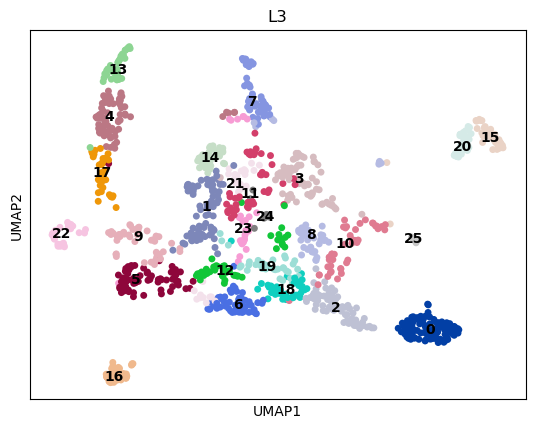

In [292]:
sc.pl.umap(an_df_clustree, color = 'L3', legend_loc='on data')

In [192]:
# fig, axs = plt.subplots(1, 3, figsize=(7.5, 2.5), dpi=300)

# axs[0].scatter(an_df_clustree.obsm['X_umap'][:, 0],
#             an_df_clustree.obsm['X_umap'][:, 1],
#             c=an_df_clustree.uns['L2_colors'][an_df_clustree.obs['L1'].values.astype(int)],
#             s=2,
#             # cmap='tab20',
#             alpha=1)

# axs[1].scatter(an_df_clustree.obsm['X_umap'][:, 0],
#             an_df_clustree.obsm['X_umap'][:, 1],
#             c=an_df_clustree.uns['L2_colors'][an_df_clustree.obs['L2'].values.astype(int)],
#             s=2,
#             # cmap='tab20',
#             alpha=1)

# axs[2].scatter(an_df_clustree.obsm['X_umap'][:, 0],
#             an_df_clustree.obsm['X_umap'][:, 1],
#             c=an_df_clustree.uns['L2_colors'][an_df_clustree.obs['L3'].values.astype(int) % 16],
#             s=2,
#             # cmap='tab20',
#             alpha=1)

Gene
pyrH    6
ispE    5
dxs     4
sigA    4
ispD    4
gapA    4
fbaA    3
walR    3
yumC    3
ispG    2
ywlF    2
eno     2
tpi     2
rplO    1
purC    1
hepT    1
pgk     1
aspB    1
purL    1
purK    1
Name: count, dtype: int64

### Steady state values parsing

,Mean: Length,Mean: Width,Mean: Volume,Mean: mCherry mean_intensity,Mean: Instantaneous Growth Rate: Volume,Mean: Septum Displacement Length Normalized
opLAG1_id,,,,,,
0.0,2.994034,1.190552,2.924343,912.099870,0.890563,0.027420
1.0,3.154474,1.180243,3.048199,935.988139,0.869343,0.026810
2.0,3.004978,1.187662,2.919528,929.123987,0.889660,0.027795
3.0,2.984890,1.192844,2.919106,934.561246,0.882916,0.027280
4.0,3.025474,1.189765,2.950071,921.134367,0.879990,0.027619
...,...,...,...,...,...,...
8478.0,2.967191,1.189729,2.884429,915.604781,0.897394,0.027792
8479.0,2.990151,1.188482,2.902446,918.967169,0.876192,0.029527
8480.0,2.987684,1.193632,2.924516,917.577469,0.892654,0.027267


In [237]:
COLS_TO_LOAD_SS = ['Mean: Length', 'Mean: Width', 'Mean: Volume','Mean: mCherry mean_intensity', 'Mean: Instantaneous Growth Rate: Volume',  'Mean: Septum Displacement Length Normalized', 'Mean: Delta time (s)']
df_ss = (pd
    .read_pickle(HEADPATH + "2025-08-11_lLAG8_Lineage_Cell_Cycle_Timeseries_Steady_State_MeanCV.pkl")
    .loc[:, COLS_TO_LOAD_SS]
    .loc[df_clusters.index]
)

In [238]:
df_ss

,Mean: Length,Mean: Width,Mean: Volume,Mean: mCherry mean_intensity,Mean: Instantaneous Growth Rate: Volume,Mean: Septum Displacement Length Normalized,Mean: Delta time (s)
opLAG1_id,,,,,,,
1.0,3.154474,1.180243,3.048199,935.988139,0.869343,0.026810,2602.268543
14.0,4.449245,1.168633,4.345467,994.691090,0.828867,0.060458,2496.116166
15.0,3.527318,1.178815,3.440917,927.843431,0.868162,0.035035,2592.997603
18.0,3.403436,1.178370,3.304891,930.140889,0.873929,0.033538,2584.179696
19.0,3.503668,1.176282,3.401939,937.673011,0.857872,0.037887,2677.635863
...,...,...,...,...,...,...,...
7939.0,2.964374,1.178002,2.827577,975.592790,0.817931,0.027966,2916.772432
7940.0,2.895679,1.174800,2.739302,967.188755,0.846279,0.028474,2873.968902
7942.0,2.918708,1.173055,2.755698,1022.672101,0.764427,0.028335,3014.537998


In [204]:
an_df_clustree.obsm['X_umap'][:, 0].shape

(1209,)

In [206]:
df_clusters['Mean_Width']

opLAG1_id
1.0       1.203643
14.0      1.203643
15.0      1.203643
18.0      1.203643
19.0      1.203643
            ...   
7939.0    1.203643
7940.0    1.203643
7942.0    1.203643
7959.0    1.203643
7972.0    1.203643
Name: Mean_Width, Length: 1209, dtype: float64

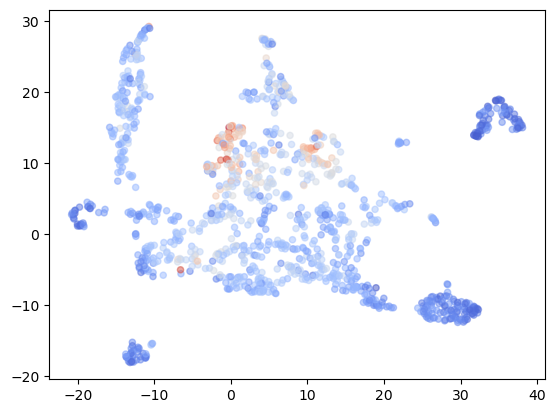

In [248]:
COLS_TO_LOAD_SS = ['Mean: Length', 'Mean: Width', 'Mean: mCherry mean_intensity', 'Mean: Instantaneous Growth Rate: Volume',  'Mean: Septum Displacement Length Normalized', 'Mean: Delta time (s)']
plt.scatter(an_df_clustree.obsm['X_umap'][:, 0],
            an_df_clustree.obsm['X_umap'][:, 1],
            c=df_ss['Mean: Delta time (s)'].values,
            s=20,
            cmap='coolwarm',
            alpha=0.5)

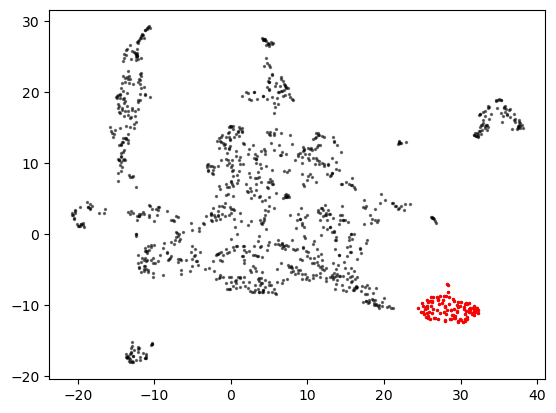

In [132]:
indices_filtered = np.where((X_umap[:, 0]> 22) & (X_umap[:, 1] < -5))
X_umap_filtered = X_umap[indices_filtered]
plt.scatter(X_umap[:, 0], X_umap[:, 1], s=2, c='black', alpha=0.5)
plt.scatter(X_umap_filtered[:, 0], X_umap_filtered[:, 1], s=2, c='red', alpha=1)

In [134]:
indices_filtered

(array([   0,   10,   17,   40,   61,   64,   66,  106,  144,  154,  160,
         162,  179,  204,  205,  219,  245,  246,  284,  287,  294,  295,
         299,  322,  328,  337,  345,  346,  347,  350,  352,  367,  383,
         408,  442,  455,  456,  457,  459,  461,  525,  526,  528,  529,
         545,  561,  562,  570,  583,  589,  611,  615,  616,  621,  622,
         637,  655,  677,  715,  720,  781,  792,  806,  865,  874,  894,
         895,  896,  899,  905,  907,  911,  914,  928,  939,  948,  980,
         981,  984,  985, 1012, 1015, 1016, 1032, 1034, 1058, 1059, 1060,
        1063, 1064, 1076, 1084, 1086, 1095, 1099, 1101, 1102, 1118, 1123,
        1146, 1147, 1161, 1178, 1195, 1201]),)

In [150]:
an_df_clustree.obs['L3'] == '0'

opLAG1_id
1.0        True
14.0      False
15.0      False
18.0      False
19.0      False
          ...  
7939.0    False
7940.0    False
7942.0    False
7959.0    False
7972.0    False
Name: L3, Length: 1209, dtype: bool

In [151]:
an_df_clustree.obs.loc[an_df_clustree.obs['L3'] == '0', 'Gene'].value_counts().sort_values(ascending=False).head(20)

Gene
clpP    3
pbpB    3
guaB    2
purE    2
ilvD    2
adk     2
rpsO    2
leuA    2
panC    2
rplP    2
tsf     2
rplV    2
ydiP    2
rplF    2
gatA    1
trpD    1
trpC    1
ylqG    1
pycA    1
hisA    1
Name: count, dtype: int64

In [138]:
an_df_clustree.obs.iloc[indices_filtered]

,Gene,Mean_Delta_time_hr,Mean_Septum_Displacement_Length_Normalized,Mean_Length,Mean_Width,Mean_mCherry_mean_intensity,Mean_Instantaneous_Growth_Rate_Volume,Delta_time_hr_Integrated_Zscore,Septum_Displacement_Length_Normalized_Integrated_Zscore,Length_Integrated_Zscore,...,Gene_Min_Recall_L3,Gene_Top2_Recall_L3,Silhouette_Score_L0,Top_2_Genes_L0,Silhouette_Score_L1,Top_2_Genes_L1,Silhouette_Score_L2,Top_2_Genes_L2,Silhouette_Score_L3,Top_2_Genes_L3
opLAG1_id,,,,,,,,,,,,,,,,,,,,,
1.0,dnaA,0.730244,0.023839,2.935581,1.203643,917.344086,0.872596,0.106360,0.035762,0.128533,...,0.111111,1.0,0.519514,rnjA\nprfB,0.526974,pbpB\nclpP,0.480023,pbpB\nclpP,0.296680,pbpB\nclpP
48.0,gyrB,0.738254,0.027933,2.935581,1.203643,917.389493,0.905876,0.068580,0.315181,0.001173,...,0.111111,1.0,0.528646,rnjA\nprfB,0.429609,pbpB\nclpP,0.381249,pbpB\nclpP,0.094453,pbpB\nclpP
79.0,gyrA,0.708210,0.025745,2.935581,1.203643,917.305341,0.926694,-0.051621,-0.196279,0.010878,...,0.111111,1.0,0.590347,rnjA\nprfB,0.651113,pbpB\nclpP,0.624746,pbpB\nclpP,0.542041,pbpB\nclpP
326.0,hprT,0.712035,0.027706,2.935581,1.203643,917.197315,0.910915,-0.101442,0.201540,0.038466,...,0.111111,1.0,0.667630,rnjA\nprfB,0.745548,pbpB\nclpP,0.723257,pbpB\nclpP,0.636274,pbpB\nclpP
439.0,ispF,0.663523,0.020948,2.935581,1.203643,916.487926,0.886807,0.032847,-0.206145,0.088108,...,0.111111,1.0,0.596032,rnjA\nprfB,0.569377,pbpB\nclpP,0.527800,pbpB\nclpP,0.439271,pbpB\nclpP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7506.0,hisA,0.747749,0.030637,2.935581,1.203643,917.275384,0.926767,-0.069990,0.146454,0.040168,...,0.111111,1.0,0.672806,rnjA\nprfB,0.719784,pbpB\nclpP,0.697602,pbpB\nclpP,0.629158,pbpB\nclpP
7575.0,hisD,0.740712,0.026192,2.935581,1.203643,917.394665,0.903403,-0.006051,0.005253,-0.005686,...,0.111111,1.0,0.665789,rnjA\nprfB,0.739526,pbpB\nclpP,0.713876,pbpB\nclpP,0.617361,pbpB\nclpP
7643.0,cysL,0.727726,0.027091,2.935581,1.203643,917.337391,0.938127,-0.002194,0.144129,0.025516,...,0.111111,1.0,0.664134,rnjA\nprfB,0.742951,pbpB\nclpP,0.724348,pbpB\nclpP,0.646253,pbpB\nclpP


In [ ]:
an_df_clustree

In [137]:
an_df_clustree.obs.iloc[indices_filtered]['Gene'].value_counts().head(50)

Gene
clpP        3
pbpB        3
rplF        2
ydiP        2
rplV        2
tsf         2
rplP        2
panC        2
guaB        2
rpsO        2
adk         2
leuA        2
ilvD        2
purE        2
hisJ        1
hemQ        1
rrnW-23S    1
hisF        1
hprT        1
hisD        1
ilvA        1
hepT        1
secA        1
ywlF        1
hemE        1
sigA        1
sknR        1
gyrA        1
groES       1
gpsA        1
sufD        1
sufU        1
gltC        1
glmS        1
tagG        1
tagO        1
gyrB        1
rpsI        1
rpsQ        1
ispF        1
pyrK        1
racE        1
proS        1
prfB        1
rnz         1
pdhC        1
rplJ        1
patA        1
rplM        1
panD        1
Name: count, dtype: int64

In [124]:
# Get cluster centroids
print(an_df_clustree.uns.keys())
an_df_clustree.uns['paga']

dict_keys(['L2_colors', 'L2_sizes', 'leiden', 'neighbors', 'paga', 'umap'])


{'connectivities': <16x16 sparse matrix of type '<class 'numpy.float64'>'
 	with 120 stored elements in Compressed Sparse Row format>,
 'connectivities_tree': <16x16 sparse matrix of type '<class 'numpy.float64'>'
 	with 15 stored elements in Compressed Sparse Row format>,
 'groups': 'L2',
 'pos': array([[ 1.82887243e+00, -1.39444575e+00],
        [ 3.53025841e-01, -4.77810821e-02],
        [-8.04188981e-01,  5.38827984e-01],
        [ 7.45430555e-01, -1.25664784e+00],
        [ 3.83481594e+00, -1.67323440e+00],
        [-7.10791786e-02, -8.90707575e-01],
        [ 7.38945700e-01,  5.61600719e-01],
        [ 1.61252923e+00,  4.93463960e-02],
        [ 3.42485382e+00, -1.43856313e-03],
        [-8.11903384e-01, -1.57440772e+00],
        [ 1.35706979e+00, -5.99268695e-01],
        [ 2.40141033e+00, -5.47479715e-01],
        [-1.50122641e+00,  1.74256427e+00],
        [-1.83756900e+00, -2.95595843e+00],
        [-1.92849865e+00, -6.35320111e-01],
        [ 7.96039243e-01, -4.75305490e-01]

In [64]:
X_umap = an_df_clustree.obsm['X_umap']

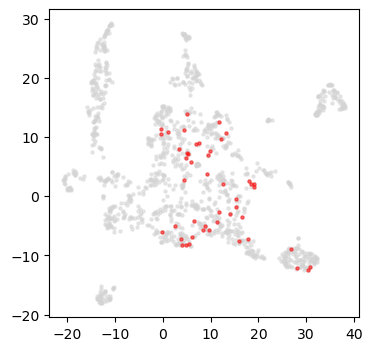

In [125]:
genes_divisome = ["divIB", "divIC", "ezrA", "ftsA", "ftsL", "ftsW", "ftsZ", "pbpB", "sepF", "zapA"]
genes_division_other = ["ddcA", "disA", "divIVA", "dynA", "facZ", "ftsH", "gpsB", "mciZ", "noc", "plsX", "racA", "rasP", "refZ", "sftA", "spoVG", "tseB", "ugtP", "walJ", "whiA", "yerH", "yisK", "yneA", "yodL", "ypbE", "yrrS"]
genes_cell_wall_precursors = ["alr", "amj", "asd", "dapA", "dapB", "dapF", "dapG", "dat", "ddl", "gcaD", "glmM", "glmR", "glmS", "ldcB", "ldt", "mraY", "murAA", "murAB", "murB", "murC", "murD", "murE", "murF", "murG", "murJ", "patA", "pgcA", "racE", "spoVB", "spoVE", "uptA", "walJ", "yabM", "yciB", "ykuQ", "ykuR", "ylmD", "yrpC"]
genes_teichoic_acid = ["dltA", "dltB", "dltC", "dltD", "dltE", "dltX", "ggaA", "ggaB", "gtaB", "gtcA", "mnaA", "pgcA", "tagA", "tagB", "tagC", "tagD", "tagE", "tagF", "tagG", "tagH", "tagO", "yngA"]
genes_pbp = ["dacA", "dacB", "dacC", "dacF", "pbpA", "pbpB", "pbpC", "pbpD", "pbpE", "pbpF", "pbpG", "pbpH", "pbpI", "pbpX", "ponA", "spoVD"]
genes_shape = ["cwlO", "dacA", "dynA", "ftsE", "ftsX", "glmR", "guaA", "ltaS", "lytE", "mbl", "minJ", "mreB", "mreBH", "mreC", "mreD", "murB", "panD", "pbpA", "ponA", "ptsH", "pyk", "rodA", "rodZ", "rpeA", "tagA", "tagO", "tseB", "ugtP", "yaaA", "ybzH", "yfnI", "yqgS", "yubA", "yueF"]
genes_segregation = ["codV", "gyrA", "gyrB", "hbs", "parA", "parB", "parC", "parE", "rok", "scpA", "scpB", "sftA", "smc", "spoIIIE", "topA", "topB", "whiA", "xerD"]

genes_rproteins = ["ctc", "motI", "rplA", "rplB", "rplC", "rplD", "rplE", "rplF", "rplGB", "rplI", "rplJ", "rplK", "rplL", "rplM", "rplN", "rplO", "rplP", "rplQ", "rplR", "rplS", "rplT", "rplU", "rplV", "rplW", "rplX", "rpmA", "rpmB", "rpmC", "rpmD", "rpmE", "rpmEB", "rpmF", "rpmGA", "rpmGB", "rpmGC", "rpmH", "rpmI", "rpmJ", "rpsA", "rpsB", "rpsC", "rpsD", "rpsE", "rpsF", "rpsG", "rpsH", "rpsI", "rpsJ", "rpsK", "rpsL", "rpsM", "rpsN", "rpsNB", "rpsO", "rpsP", "rpsQ", "rpsR", "rpsS", "rpsT", "rpsU"]

# genes_rproteins_similarity = ["rplGA", "yfjL"] # No Phenotype
genes_ribo_assembly = ["cpgA", "cshA", "cshB", "engA", "era", "obg", "prp", "rbgA", "tlyA", "yaaA", "yfmL", "yqeH", "ysxC"]
genes_trna_modification = ["cca", "cspR", "dusB1", "dusB2", "fmt", "folD", "folE", "folEB", "gidA", "miaA", "mnmL", "mnmM", "nifZ", "pnpA", "queA", "queC", "queD", "queE", "queF", "queG", "rnpA", "rnpB", "rnpM", "rnr", "rnz", "rph", "tgt", "thdF", "thiI", "tilS", "tmcAL", "trmB", "trmD", "trmFO", "trmK", "trmN6", "trmR", "trmU", "truA", "truB", "tsaB", "tsaC", "tsaD", "tsaE", "yaaJ", "yjbO", "yloN", "ymcB", "yqeV", "yrrN", "yrrO", "yrvM", "yrvO"]
# genes_trna_modification_similarity = ['ybfQ', 'yjdI'] # No Phenotype
genes_trna_synthetases = ["alaS", "argS", "asnS", "aspS", "cysS", "gatA", "gatB", "gatC", "gltX", "glyQ", "glyS", "hisS", "hisZ", "ileS", "leuS", "lysS", "metS", "pheS", "pheT", "proS", "serS", "thrS", "thrZ", "trpS", "tyrS", "tyrZ", "valS", "ytpR"]
genes_translation_factors = ["efp", "frr", "fusA", "infA", "infB", "infC", "prfA", "prfB", "rbfA", "tsf", "tufA", "vmlR", "ydiF", "yebC2", "yfmM", "yfmR", "ykpA", "ylaG"]
genes_translation_other = ["deaD", "defA", "dtd", "map", "mifM", "pth", "yflG", "yqeL", "yqeT"]
genes_translation_other_similarity = ["prmC", "yjcK", "ylxS", "ynaD", "yqeI"]
genes_translation_factor_modification = ["gsaB", "rimI", "yaaO", "yfkA", "ymfI", "ynbB", "ywlG"]
genes_ribo_quality_control_rescue = ["brfA", "pth", "rqcH", "rqcP", "rqcU", "scpB", "smpB", "ssrA", "ylmH", "yocB"]
genes_men = ['hepS', 'hepT', 'menA', 'menB', 'menC', 'menD', 'menE', 'menF', 'menH']
genes_hem = ['hemA', 'hemB', 'hemC', 'hemD', 'hemE', 'hemF', 'hemG', 'hemH', 'hemL', 'hemN', 'hemQ', 'hemT', 'hemY']
genes_fatty_acid = ["cotR", "glpD", "glpP", "glpQ", "glpT", "lipC", "yhdW", "yqiK", "acdA", "acsA", "acuA", "acuC", "etfA", "etfB", "fadA", "fadB", "fadE", "fadF", "fadG", "fadH", "fadM", "fadN", "fadR", "lcfA", "lcfB", "scoA", "scoB", "lip", "lipB", "nap", "pnbA", "accA", "accB", "accC", "accD", "acpA", "acpS", "birA", "fabD", "fabF", "fabG", "fabHA", "fabHB", "fabI", "fabL", "fapR", "plsC", "plsX", "ycsD", "yhdN", "ywpB", "cdsA", "clsA", "degV", "fakA", "gpsA", "mprF", "petA", "pgpB", "pgpP", "pgsA", "plsY", "psd", "pssA", "yitS", "ywiE", "ywjE", "dxs", "fni", "ispC", "ispD", "ispE", "ispF", "ispG", "ispH", "nudF", "uppS", "yhfR", "yisP", "yqiD", "cypC", "des", "desK", "desR", "fatR", "gtaB", "pcrB", "pgcA", "trhA", "ugtP", "yetO", "yjiB", "yrhJ"]
genes_carbon = ["cggR", "eno", "fbaA", "gapA", "glcT", "mgsA", "pfkA", "pgi", "pgk", "pgm", "ptsG", "pyk", "tpi", "ccpN", "fbp", "gapB", "glpX", "pckA", "yqfL", "gndA", "rpeA", "tkt", "ykgB", "ywjH", "ywlF", "zwf", "ccpC", "citB", "citG", "citZ", "icd", "mdh", "odhA", "odhB", "pdhA", "pdhB", "pdhC", "pdhD", "pdhI", "pycA", "sdhA", "sdhB", "sdhC", "sucC", "sucD", "ackA", "alsD", "alsR", "alsS", "bdhA", "lctP", "ldh", "pta", "rex"]
glycolysis_genes = ["cggR", "eno", "fbaA", "gapA", "glcT", "mgsA", "pfkA", "pgi", "pgk", "pgm", "ptsG", "pyk", "tpi"]

genes_to_filter = genes_trna_synthetases
filtering_mask = an_df_clustree.obs['Gene'].isin(genes_to_filter)
# filtering_mask = an_df_clustree.obs['Gene'].str.startswith('hem')
X_umap_filtered = X_umap[filtering_mask]

plt.figure(figsize=(4, 4))

plt.scatter(X_umap[:, 0],
            X_umap[:, 1],
            c='lightgray',
            s=5,
            alpha=0.5)

plt.scatter(X_umap_filtered[:, 0],
            X_umap_filtered[:, 1],
            c='red',
            s=5,
            alpha=0.5)

In [ ]:


an_df_clustree.obs['Gene'].isin(genes_divisome).values

array([False, False, False, ..., False, False, False])